<a href="https://colab.research.google.com/github/APihadddadene/Judicial_TAT_LDA_Graph_Network/blob/02_Network_Graph/02_Network_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#02\. Network exploration

## 1\. Package installation

In [ ]:
# Package installation
!pip install pyvis

from IPython.display import HTML, display
import pandas as pd
import networkx as nx
from pyvis.network import Network
import matplotlib.pyplot as plt
from google.colab import drive
from numpy import minimum, maximum

In [ ]:
# 1. Mount Google Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2\. Import Dataframes
***Note***:
- We imported clean nodes and edges that were manualy sorted into gephi. Here we are using dataframes from gephi.
- In the manual cleaning was mostly a standardization of laws formats and suppression of artefact left from regex extraction. we are talking about 20/30 cases of artefacts.



In [ ]:
# 2. Define the path for dataframes
edges_path = "/content/drive/MyDrive/02.Memoire/Data/06-network/2-edges_final.xlsx"
nodes_path = "/content/drive/MyDrive/02.Memoire/Data/06-network/2-nodes_final.xlsx"

In [ ]:
# 3. Open the dataframes
edges_dtf = pd.read_excel(edges_path)
nodes_dtf = pd.read_excel(nodes_path)

nodes_dtf.drop(columns=["Label"], inplace=True) # Gephi Label is a feature that we do not use because we have our own labels.

print(f"Edges head :\n-------------\n {edges_dtf.head()}")
print(f"\n---------------------------------------------------------------------------\n")
print(f"\nNodes head :\n------------\n {nodes_dtf.head()}")

Edges head :
-------------
    Source labels_source  Target               labels_target
0     889  2017QCTAT992    8943               2005QCCRT0396
1       1    2017QCTAT1   16592  rlrq,c.a-3.001.,article365
2       9   2017QCTAT10   16601   rlrq,c.a-3.001.,article28
3       9   2017QCTAT10   16602  rlrq,c.a-3.001.,article212
4     889  2017QCTAT992   16847    rlrq,c.n-1.1.,article122

---------------------------------------------------------------------------


Nodes head :
------------
       Id                          labels type  componentnumber  \
0  16991             l.r.c(1985),c.c-46.  Loi                0   
1  17382  l.r.c(1985),c.c-46.,article264  Loi                0   
2  17383  l.r.c(1985),c.c-46.,article265  Loi                0   
3  17431              l.r.c(1985),c.g-5.  Loi                0   
4  16739     l.r.c(1985),c.g-5.,article2  Loi                0   

   modularity_class  indegree  outdegree  degree  stat_inf_class  \
0                 5         2          5 

## 3\. descriptive stats

### 3.a) General graph statistics

In [ ]:
# Get basic graph statistics
print(f"Number of nodes :{len(nodes_dtf)}")
print(f"Number of edges :{len(edges_dtf)}")
print(f"Average degree : {nodes_dtf["degree"].mean()}")
print(f"---------------------------------------------")
print(f"Number of reference text :{(nodes_dtf['type'] == 'text').sum()}")
print(f"Number of laws :{(nodes_dtf['type'] == 'Loi').sum()}")
print(f"Number of lawsisprudences :{(nodes_dtf['type'] == 'Reference').sum()}")

Number of nodes :17447
Number of edges :65866
Average degree : 7.550409812575228
---------------------------------------------
Number of reference text :5403
Number of laws :856
Number of lawsisprudences :11187


### 3.b) Total quotation exploration

In [ ]:
# 1. Filtering out nodes_dtf to keep only corpus node
corpus_filtered_nodes = nodes_dtf[nodes_dtf['type'] == 'text']
corpus_filtered_nodes

,Id,labels,type,componentnumber,modularity_class,indegree,outdegree,degree,stat_inf_class,strongcompnum
12043,5403,2017QCTAT5936,text,0,9,0,2,2,285,12035
12044,5402,2017QCTAT5935,text,0,11,0,4,4,13,12037
12045,5401,2017QCTAT5933,text,0,17,0,17,17,138,12041
12046,5400,2017QCTAT5932,text,0,4,0,9,9,160,12042
12047,5399,2017QCTAT5931,text,0,8,0,4,4,223,12043
...,...,...,...,...,...,...,...,...,...,...
17441,5,2017QCTAT6,text,0,7,0,4,4,230,17356
17442,4,2017QCTAT5,text,0,4,0,11,11,251,17357
17443,3,2017QCTAT4,text,0,18,0,11,11,212,17358
17444,2,2017QCTAT3,text,0,9,0,7,7,318,17359


In [ ]:
# 2. Getting statistics on the corpus quotations
quot_min = corpus_filtered_nodes["outdegree"].min()
quot_Q1 = corpus_filtered_nodes["outdegree"].quantile(0.25)
quot_mean = corpus_filtered_nodes["outdegree"].mean()
quot_med = corpus_filtered_nodes["outdegree"].median()
quot_Q3 = corpus_filtered_nodes["outdegree"].quantile(0.75)
quot_max = corpus_filtered_nodes["outdegree"].max()
quot_std_dev = corpus_filtered_nodes["outdegree"].std()

print(f"Minimum of quotations per corpus text : {quot_min}")
print(f"Q1 of quotations per corpus text : {quot_Q1}")
print(f"Mean of quotations per corpus text : {quot_mean}")
print(f"Median of quotations per corpus text : {quot_med}")
print(f"Q3 of quotations per corpus text : {quot_Q3}")
print(f"Maximum of quotations per corpus text : {quot_max}")
print(f"Standard deviation of quotations per corpus text : {quot_std_dev}")

Minimum of quotations per corpus text : 0
Q1 of quotations per corpus text : 5.0
Mean of quotations per corpus text : 12.040718119563206
Median of quotations per corpus text : 8.0
Q3 of quotations per corpus text : 15.0
Maximum of quotations per corpus text : 105
Standard deviation of quotations per corpus text : 11.756311309742035


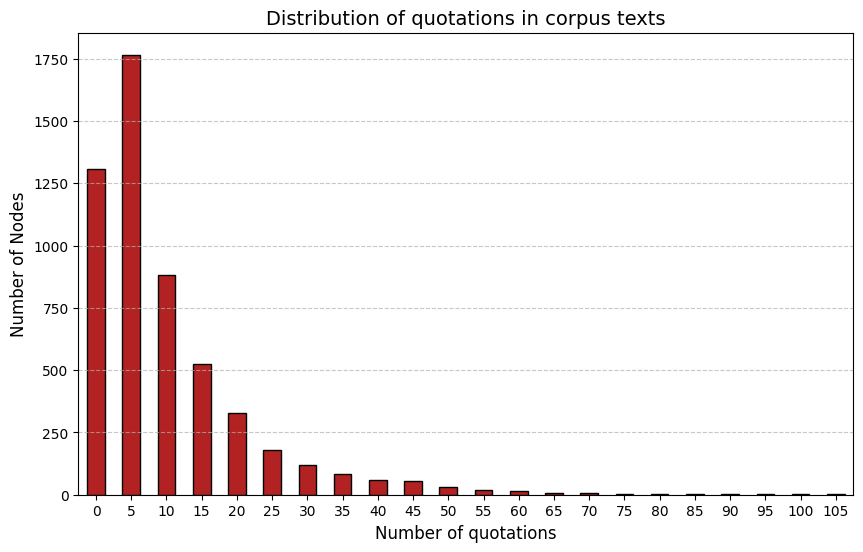

In [ ]:
# 3. plot distribution
# Get maximum out_degree and create size 5 bins for visualization
max_val = int(corpus_filtered_nodes['outdegree'].max())
bins = list(range(0, max_val + 6, 5))

# Group outdegrees instide bins
binned_data = pd.cut(corpus_filtered_nodes['outdegree'], bins=bins, right=False)

# Determine frequencies of each brackets
outdegree_counts = binned_data.value_counts().sort_index()

# Plot bar chart
ax = outdegree_counts.plot(kind='bar', figsize=(10, 6), color='firebrick', edgecolor='black')

# Getting ticks to be in readable format
tick_positions = range(0, len(bins) - 1)
tick_labels = bins[:-1]

plt.xticks(ticks=tick_positions, labels=tick_labels, rotation=0)

# Add aestetic elements in the graph
plt.title('Distribution of quotations in corpus texts', fontsize=14)
plt.xlabel('Number of quotations', fontsize=12)
plt.ylabel('Number of Nodes', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot the bar chart
plt.show()

### 3.c) Jurisprudencial exploration

In [ ]:
# 1. Filtering out nodes_dtf to keep the jurisprudence connexions
merged = edges_dtf.merge(
    nodes_dtf.rename(columns={'Id': 'source_id', 'type': 'source_type'}),
    left_on='Source',
    right_on='source_id'
).merge(
    nodes_dtf.rename(columns={'Id': 'target_id', 'type': 'target_type'}),
    left_on='Target',
    right_on='target_id'
)[['source_id', 'source_type', 'target_id', 'target_type']]

filtered = merged[
    (merged['source_type'] == 'text') &
    (merged['target_type'] == 'Reference')
]

text_nodes = nodes_dtf[nodes_dtf['type'] == 'text'][['Id']].rename(columns={'Id': 'source_id'})

# Count the number of connections for each text node that has at least one
counts = filtered.groupby('source_id').size().reset_index(name='line_count')

# Left join all text nodes with the counts, filling missing values with 0
result = text_nodes.merge(counts, on='source_id', how='left').fillna({'line_count': 0})

# Ensure the count column is an integer
result['line_count'] = result['line_count'].astype(int)

result

,source_id,line_count
0,5403,0
1,5402,1
2,5401,11
3,5400,6
4,5399,0
...,...,...
5398,5,0
5399,4,7
5400,3,7
5401,2,2


In [ ]:
# 2. Getting statistics on the corpus jurisprudences quotations
jur_min = result["line_count"].min()
jur_Q1 = result["line_count"].quantile(0.25)
jur_mean = result["line_count"].mean()
jur_med = result["line_count"].median()
jur_Q3 = result["line_count"].quantile(0.75)
jur_max = result["line_count"].max()
jur_std_dev = result["line_count"].std()

print(f"Minimum of jurisprudences per corpus text : {jur_min}")
print(f"Q1 of jurisprudences per corpus text : {jur_Q1}")
print(f"Median of jurisprudences per corpus text : {jur_med}")
print(f"Mean of jurisprudences per corpus text : {jur_mean}")
print(f"Q3 of jurisprudences per corpus text : {jur_Q3}")
print(f"Maximum of jurisprudences per corpus text : {jur_max}")
print(f"Standard deviation of jurisprudences per corpus text : {jur_std_dev}")

Minimum of jurisprudences per corpus text : 0
Q1 of jurisprudences per corpus text : 1.0
Median of jurisprudences per corpus text : 4.0
Mean of jurisprudences per corpus text : 7.40792152507866
Q3 of jurisprudences per corpus text : 10.0
Maximum of jurisprudences per corpus text : 88
Standard deviation of jurisprudences per corpus text : 9.766838817953142


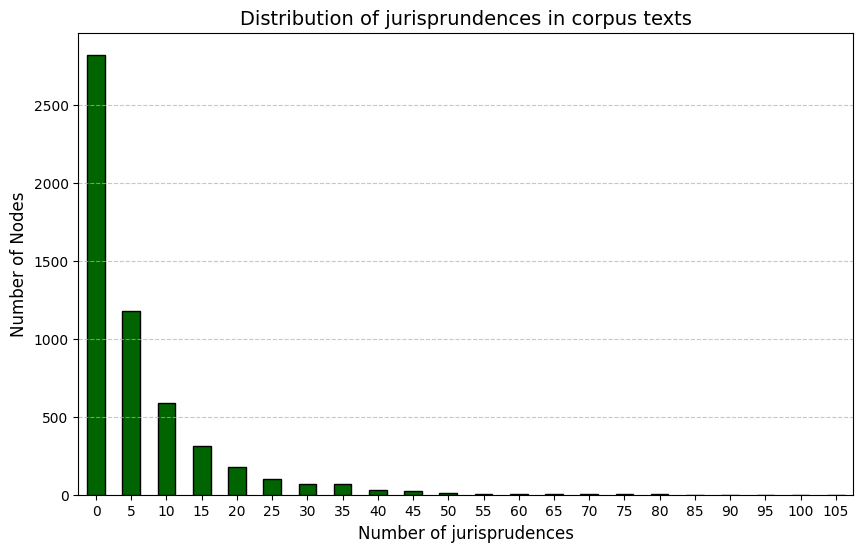

In [ ]:
# 3. plot distribution
# Get maximum out_degree and create size 5 bins for visualization
max_val = int(result['line_count'].max())

# Group outdegrees instide bins
binned_data = pd.cut(result['line_count'], bins=bins, right=False)

# Determine frequencies of each brackets
outdegree_counts = binned_data.value_counts().sort_index()

# Plot bar chart
ax = outdegree_counts.plot(kind='bar', figsize=(10, 6), color='darkgreen', edgecolor='black')

# Getting ticks to be in readable format
tick_positions = range(0, len(bins) - 1)
tick_labels = bins[:-1]

plt.xticks(ticks=tick_positions, labels=tick_labels, rotation=0)

# Add aestetic elements in the graph
plt.title('Distribution of jurisprundences in corpus texts', fontsize=14)
plt.xlabel('Number of jurisprudences', fontsize=12)
plt.ylabel('Number of Nodes', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot the bar chart
plt.show()

3.d) Laws exploration

In [ ]:
# 1. Filtering out nodes_dtf to keep the laws connexions
merged = edges_dtf.merge(
    nodes_dtf.rename(columns={'Id': 'source_id', 'type': 'source_type'}),
    left_on='Source',
    right_on='source_id'
).merge(
    nodes_dtf.rename(columns={'Id': 'target_id', 'type': 'target_type'}),
    left_on='Target',
    right_on='target_id'
)[['source_id', 'source_type', 'target_id', 'target_type']]

filtered = merged[
    (merged['source_type'] == 'text') &
    (merged['target_type'] == 'Loi')
]

text_nodes = nodes_dtf[nodes_dtf['type'] == 'text'][['Id']].rename(columns={'Id': 'source_id'})

# Count the number of connections for each text node that has at least one
counts = filtered.groupby('source_id').size().reset_index(name='line_count')

# Left join all text nodes with the counts, filling missing values with 0
result = text_nodes.merge(counts, on='source_id', how='left').fillna({'line_count': 0})

# Ensure the count column is an integer
result['line_count'] = result['line_count'].astype(int)

result

,source_id,line_count
0,5403,2
1,5402,2
2,5401,3
3,5400,3
4,5399,4
...,...,...
5398,5,4
5399,4,4
5400,3,4
5401,2,5


In [ ]:
# 2. Getting statistics on the corpus laws quotations
laws_min = result["line_count"].min()
laws_Q1 = result["line_count"].quantile(0.25)
laws_mean = result["line_count"].mean()
laws_med = result["line_count"].median()
laws_Q3 = result["line_count"].quantile(0.75)
laws_max = result["line_count"].max()
laws_std_dev = result["line_count"].std()

print(f"Minimum of laws per corpus text : {laws_min}")
print(f"Q1 of laws per corpus text : {laws_Q1}")
print(f"Median of laws per corpus text : {laws_med}")
print(f"Mean of laws per corpus text : {laws_mean}")
print(f"Q3 of laws per corpus text : {laws_Q3}")
print(f"Maximum of laws per corpus text : {laws_max}")
print(f"Standard deviation of laws per corpus text : {laws_std_dev}")

Minimum of laws per corpus text : 0
Q1 of laws per corpus text : 2.0
Median of laws per corpus text : 4.0
Mean of laws per corpus text : 4.375347029428095
Q3 of laws per corpus text : 5.0
Maximum of laws per corpus text : 31
Standard deviation of laws per corpus text : 3.182025492013732


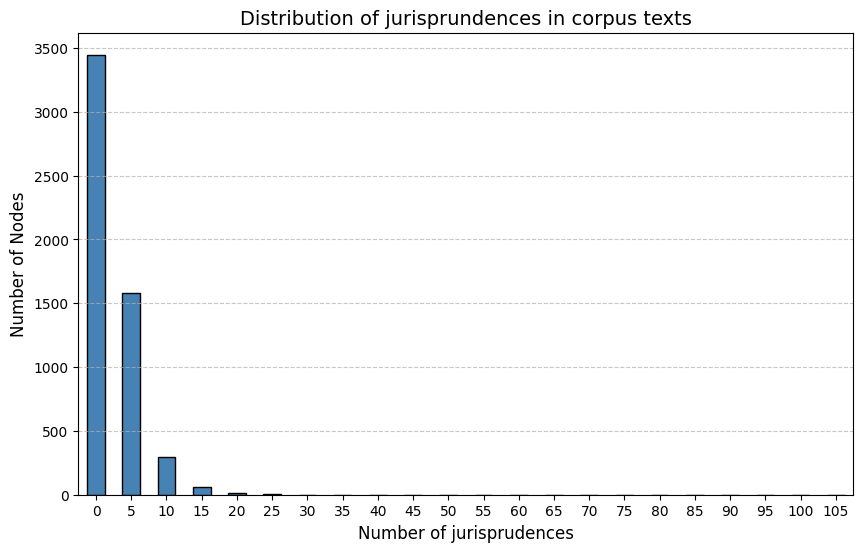

In [ ]:
# 3. plot distribution
# Get maximum out_degree and create size 5 bins for visualization
max_val = int(result['line_count'].max())

# Group outdegrees instide bins
binned_data = pd.cut(result['line_count'], bins=bins, right=False)

# Determine frequencies of each brackets
outdegree_counts = binned_data.value_counts().sort_index()

# Plot bar chart
ax = outdegree_counts.plot(kind='bar', figsize=(10, 6), color='steelblue', edgecolor='black')

# Getting ticks to be in readable format
tick_positions = range(0, len(bins) - 1)
tick_labels = bins[:-1]

plt.xticks(ticks=tick_positions, labels=tick_labels, rotation=0)

# Add aestetic elements in the graph
plt.title('Distribution of jurisprundences in corpus texts', fontsize=14)
plt.xlabel('Number of jurisprudences', fontsize=12)
plt.ylabel('Number of Nodes', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Plot the bar chart
plt.show()

### 3.d) Recap dataframe

In [ ]:

data = {
    'minimum': [quot_min, jur_min, laws_min],
    'Q1': [quot_Q1, jur_Q1, laws_Q1],
    'median': [quot_med, jur_med, laws_med],
    'mean': [quot_mean, jur_mean, laws_mean],
    'Q3': [quot_Q3, jur_Q3, laws_Q3],
    'maximum': [quot_max, jur_max, laws_max],
    'standard-deviation': [quot_std_dev, jur_std_dev, laws_std_dev]
}

# 2. Define the row index names
row_labels = ['quotations', 'jurisprudences', 'laws']

# 3. Create the DataFrame
summary_df = pd.DataFrame(data, index=row_labels)

summary_df

,minimum,Q1,median,mean,Q3,maximum,standard-deviation
quotations,0,5.0,8.0,12.040718,15.0,105,11.756311
jurisprudences,0,1.0,4.0,7.407922,10.0,88,9.766839
laws,0,2.0,4.0,4.375347,5.0,31,3.182025
